In [2]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch
from skimage import io
from glob import glob
import anndata as ad
import scanpy as sc
import seaborn as sns
import awkward as ak
import pickle
import torch

%load_ext autoreload
%autoreload 2

In [3]:
# Add base dir to path
import sys
sys.path.insert(0, '../')

In [4]:
# Make color palette for all groups we'll come across
tmp_patterns = ["small-intestine","random", "intranuclear", "nuclear-edge", "extranuclear", "foci", "protrusion", "cell-edge", "perinuclear", 
                         "pericellular","pattern"]
def get_cmap(n, name='tab10'):
    ##Returns a function that maps each index in 0, 1, ..., n-1 to a distinct 
    ##RGB color; the keyword argument name must be a standard mpl colormap name.
    return plt.cm.get_cmap(name, n)

global_cmap = get_cmap(len(tmp_patterns))
# cmap = get_cmap(len(adata.obs["pattern"].unique()), name="tab10")
palette = {}
for i, el in enumerate(tmp_patterns):
    palette[el] =  global_cmap(i)
    
colorblind_palette = sns.color_palette("colorblind")

In [5]:
# Make sure seed is the same at all times, in all packages that use it
seed = 101
torch.manual_seed(seed)
import random
random.seed(seed)
np.random.seed(seed)

In [6]:
simulation_dir = Path("/path/to/output/of/simulations/") # output of training_subcellspace/create_simulations/

In [ ]:
data_dir = Path("path/to/data/dir/")

In [6]:
subcellspace = torch.load("../SubCellSpace")

In [6]:
from src.adata_utils import convertRecordToDf, decodeSubcellEmbedding, getAllDetectedTranscripts, getXYOfSingleCell, reshape_and_filter_anndata_with_index_and_mapping
from src.plotting import plotFullDataPoint, saveAFigure

In [7]:
single_cell_adata = ad.read_h5ad(data_dir / "small_intestine_data" / "adata_subcell_including_randomized_embeddings.h5ad")

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/anndata/_core/aligned_mapping.py:54: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(


In [8]:
single_cell_adata

AnnData object with n_obs × n_vars = 408 × 547
    obs: 'name', 'tile_nr', 'local_row', 'local_col', 'cell_id', 'global_row', 'global_col', 'cell_size'
    var: 'gene_name', 'gene_label'
    uns: 'detected_transcripts', 'measured_df'
    obsm: 'cell_mask', 'dapi_mask', 'detected_transcripts'
    layers: 'random_subcell_embedding', 'subcell_embedding'

In [9]:
adata = ad.read_h5ad(data_dir / "small_intestine_data" / "adata_subcell_embeddings_classified_and_subtype_and_leiden.h5ad")

In [10]:
import math
def getUnevenSubplots(num_axes):
    # Determine the grid size
    n_cols = math.ceil(math.sqrt(num_axes))
    n_rows = math.ceil(num_axes / n_cols)
    
    # Create figure
    fig = plt.figure(figsize=(8, 6))
    
    # Calculate basic sizes
    width = 0.8 / n_cols  # width of each subplot
    height = 0.8 / n_rows  # height of each subplot
    gap_x = (1 - (width * n_cols)) / (n_cols + 1)  # horizontal gap
    gap_y = (1 - (height * n_rows)) / (n_rows + 1)  # vertical gap
    
    for i in range(num_axes):
        row = i // n_cols
        col = i % n_cols
        
        # Special case: Last row has fewer elements than the rest
        if row == n_rows - 1 and num_axes % n_cols != 0:
            # Center subplots in the last row
            extra_cols = num_axes % n_cols
            col_start = (n_cols - extra_cols) / 2  # offset to center subplots
            col = i % extra_cols + col_start
            
        # Calculate position
        left = gap_x + (width + gap_x) * col
        bottom = 1 - gap_y - height - (height + gap_y) * row
        
        # Add subplot to the figure
        ax = fig.add_axes([left, bottom, width, height])
    return fig


In [11]:
gene_panel = [el for el in single_cell_adata.var_names if not any(substring in el for substring in ("Unassigned", "NegControl", "Blank"))]

In [12]:
random_adata = reshape_and_filter_anndata_with_index_and_mapping(single_cell_adata, layer="random_subcell_embedding")

In [13]:
adata, random_adata

(AnnData object with n_obs × n_vars = 3358 × 15
     obs: 'name', 'tile_nr', 'local_row', 'local_col', 'cell_id', 'global_row', 'global_col', 'cell_size', 'gene_name', 'gene_label', 'original_cell_index', 'original_gene_index', 'original_obs_index', 'original_gene_name', 'n_spots', 'n_spots_interval', 'origin', 'n_obs', 'leiden_igraph_res_0.6', 'subtype_pattern', 'final_class'
     uns: 'leiden_igraph_res_0.6_colors', 'neighbors', 'umap'
     obsm: 'X_umap'
     obsp: 'connectivities', 'distances',
 AnnData object with n_obs × n_vars = 3358 × 15
     obs: 'name', 'tile_nr', 'local_row', 'local_col', 'cell_id', 'global_row', 'global_col', 'cell_size', 'gene_name', 'gene_label', 'original_cell_index', 'original_gene_index', 'original_obs_index', 'original_gene_name', 'n_spots', 'n_spots_interval')

In [14]:
adata.obs["origin"] = "small-intestine"
random_adata.obs["origin"] = "shuffled"

In [44]:
sc.tl.pca(combined_adata, svd_solver='arpack', n_comps = adata.X.shape[1]-1)

In [45]:
n_neighbors = 25

In [46]:
sc.pp.neighbors(combined_adata, n_neighbors=n_neighbors, n_pcs=25)

In [47]:
sc.tl.umap(combined_adata)

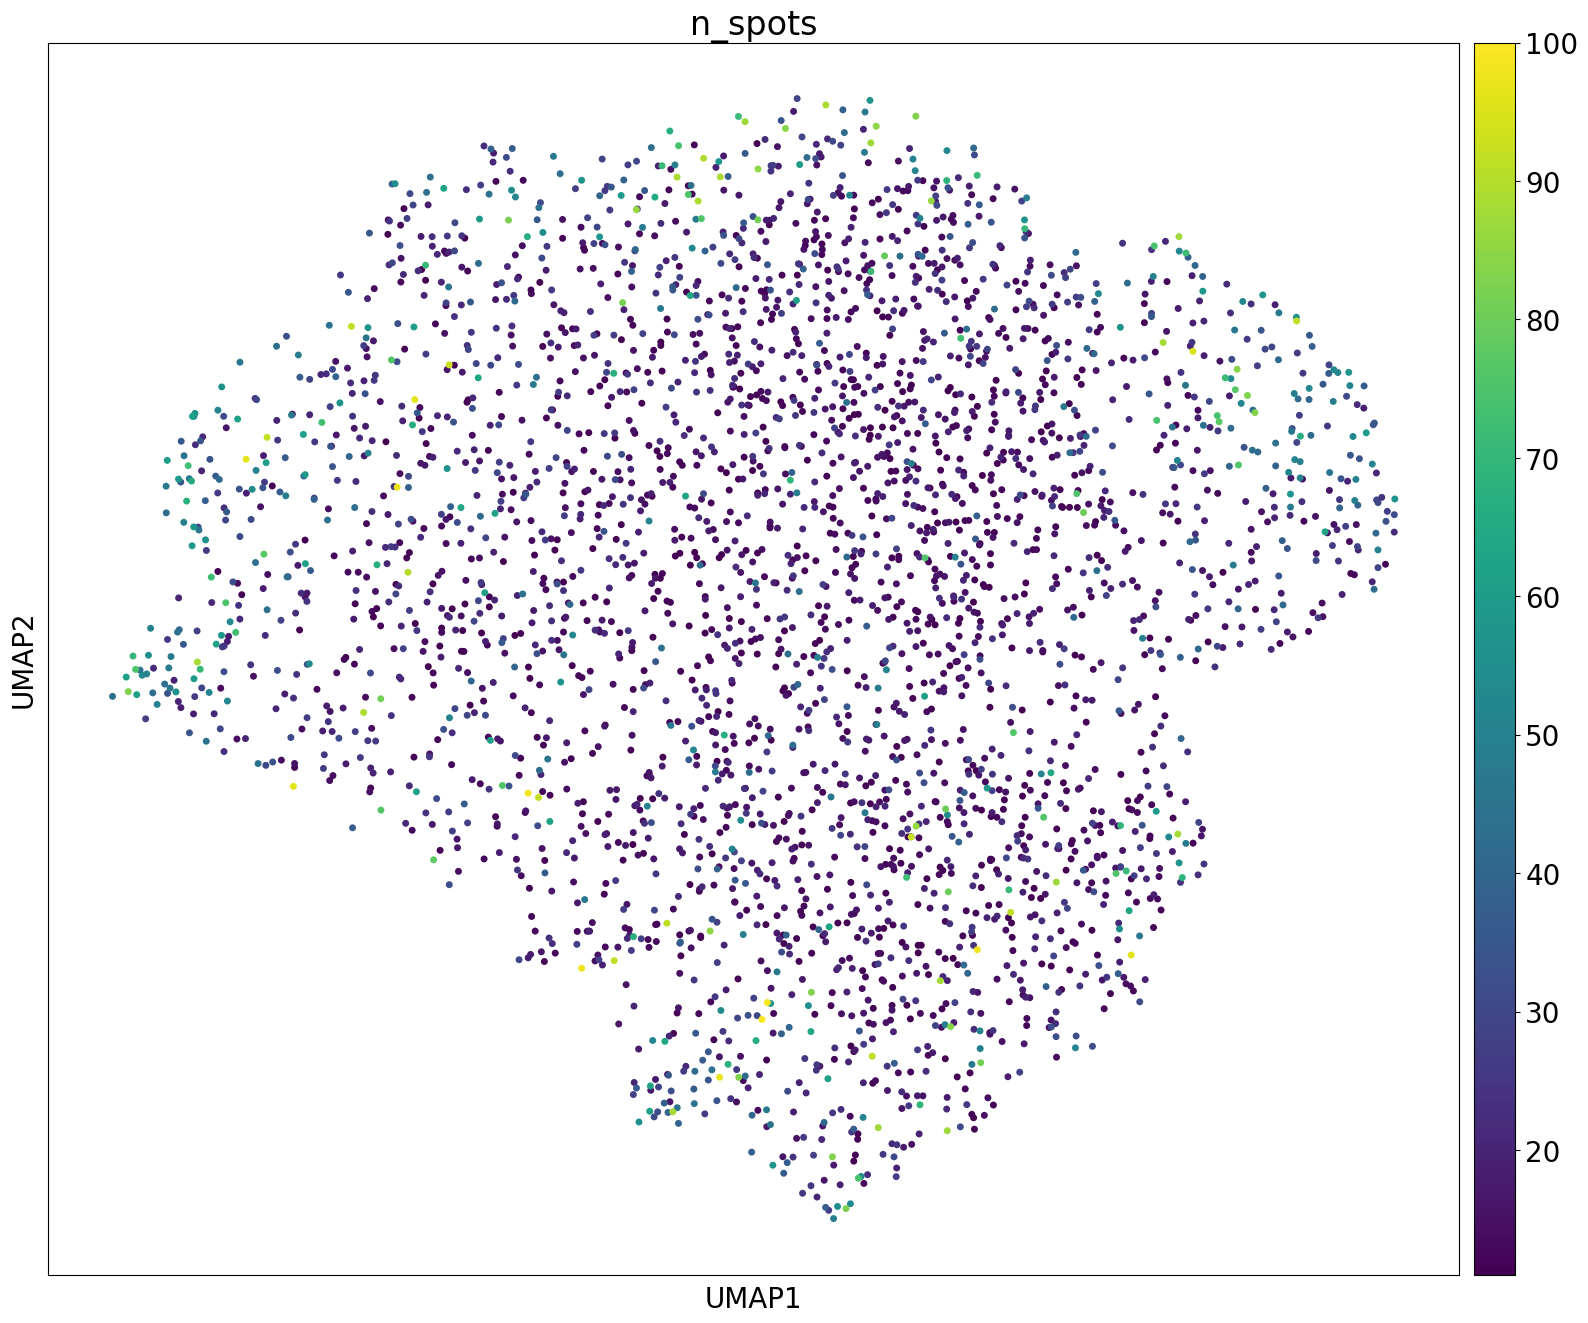

In [513]:
sc.pl.umap(adata, color="origin", s=100)

# Classify genes with randomforest

In [15]:
# First get ground truth information
xls = pd.ExcelFile('./info_files/13059_2025_3786_MOESM2_ESM.xlsx')
df = pd.read_excel(xls, '17_sIT_MERFISH_volnorm', header=4)
# from paper:basal > 0.5 and apical for <  − 0.5.

In [16]:
fc_cols = ["Villus bottom - logFC", "Villus mid - logFC", "Villus top - logFC"]


In [17]:
df["mean_fc"] = df[fc_cols].mean(axis=1)

In [18]:
apical_mask = (df[fc_cols] > 0.5).all(axis=1)
basal_mask = (df[fc_cols] < -0.5).all(axis=1)

In [19]:
df["apical"] = apical_mask
df["basal"] = basal_mask

In [20]:
apical_genes = list(df[apical_mask]["Gene names"])
basal_genes = list(df[basal_mask]["Gene names"])
polarized_genes = apical_genes + basal_genes

In [21]:
import pickle
path = '../classifiers/rf_pattern_nonpattern.pkl'
with open(path, 'rb') as p:
    classifier = pickle.load(p)

In [22]:
z = adata.obs['gene_name'].value_counts() 
z1 = z.to_dict() #converts to dictionary

adata.obs['n_obs'] = adata.obs['gene_name'].map(z1) 
random_adata.obs['n_obs'] = random_adata.obs['gene_name'].map(z1) 


In [23]:
from src.classifiers import min_observations_per_gene
tmp_adata = adata[adata.obs["n_obs"] >= min_observations_per_gene]
tmp_random_adata = random_adata[random_adata.obs["n_obs"] >= min_observations_per_gene]

In [24]:
from src.classifiers import classify_all_genes
result_df = classify_all_genes(tmp_adata, classifier, tmp_random_adata, earth_dist_threshold = 0.03, max_number_of_observations_to_consider=1000, random_seed=seed, store_adata=True)

100%|██████████| 30/30 [00:02<00:00, 13.40it/s]
/home/luna.kuleuven.be/u0147891/SubCellSpace/make_paper_figures/src/classifiers.py:132: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["earth_dist"] = dist_col


In [25]:
true_random = [str(gene) not in polarized_genes for gene in result_df["gene_name"] ]

In [26]:
result_df["true_random"] = true_random

In [27]:
cols_of_interest = ["gene_name", "n_obs", "earth_dist", "pval", "bonferonni_pval", "passes", "passes_earth_thresh", "gene_pattern", "true_random"]

In [28]:
result_df["true_random"].value_counts()

False    17
True     13
Name: true_random, dtype: int64

## Fig 6A

In [29]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
tmp_thresh = 0.03
tmp_final_preds = result_df['gene_pattern']
tmp_true_labels = ~result_df['true_random']
plt.rcParams["figure.figsize"] = [10,8]
cm = confusion_matrix(tmp_true_labels, tmp_final_preds, labels=[True, False])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Random', 'Random'])
disp.plot(cmap='Blues', values_format='d', )
plt.title(f'Confusion Matrix at Threshold = {tmp_thresh:.3f}')
plt.tight_layout()
fig = plt.gcf()
saveAFigure(fig, "moor_confusion_matrix_updated_groundtruth", out_dir=Path("/mnt/data/david/plots/manuscript/quantification/"))
plt.show()

/tmp/ipykernel_2351044/648682596.py:13: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


In [30]:
from sklearn.metrics import f1_score, precision_recall_fscore_support, precision_recall_curve,classification_report
print(classification_report(tmp_true_labels, tmp_final_preds))

              precision    recall  f1-score   support

       False       0.75      0.92      0.83        13
        True       0.93      0.76      0.84        17

    accuracy                           0.83        30
   macro avg       0.84      0.84      0.83        30
weighted avg       0.85      0.83      0.83        30



### Classify for subtypes

In [31]:
from src.classifiers import classify_all_genes_for_pattern_subtypes
path = '../classifiers/multiclass_rf.pkl'
with open(path, 'rb') as p:
    multi_classifier = pickle.load(p)

In [32]:
result_df = classify_all_genes_for_pattern_subtypes(result_df, multi_classifier)
cols_of_interest.extend(["final_class", "subtype_pattern"])

In [33]:
result_df["final_class"].value_counts()

random          16
pericellular    11
extranuclear     2
cell-edge        1
Name: final_class, dtype: int64

In [34]:
# add information to adata
result_df.index=result_df["gene_name"]
mapping = result_df["subtype_pattern"].to_dict()
adata.obs["subtype_pattern"] = adata.obs["gene_name"].map(mapping)
mapping = result_df["final_class"].to_dict()
adata.obs["final_class"] = adata.obs["gene_name"].map(mapping)

## Supp fig

In [35]:
passes_df = result_df.copy()

In [36]:
ground_truth_df = df[df["Gene names"].isin(passes_df["gene_name"])]

In [37]:
passes_df.index = list(range(len(passes_df))) # Otherwise merge complains about gene name being both a col and index
merged = ground_truth_df.merge(passes_df, left_on="Gene names", right_on="gene_name")

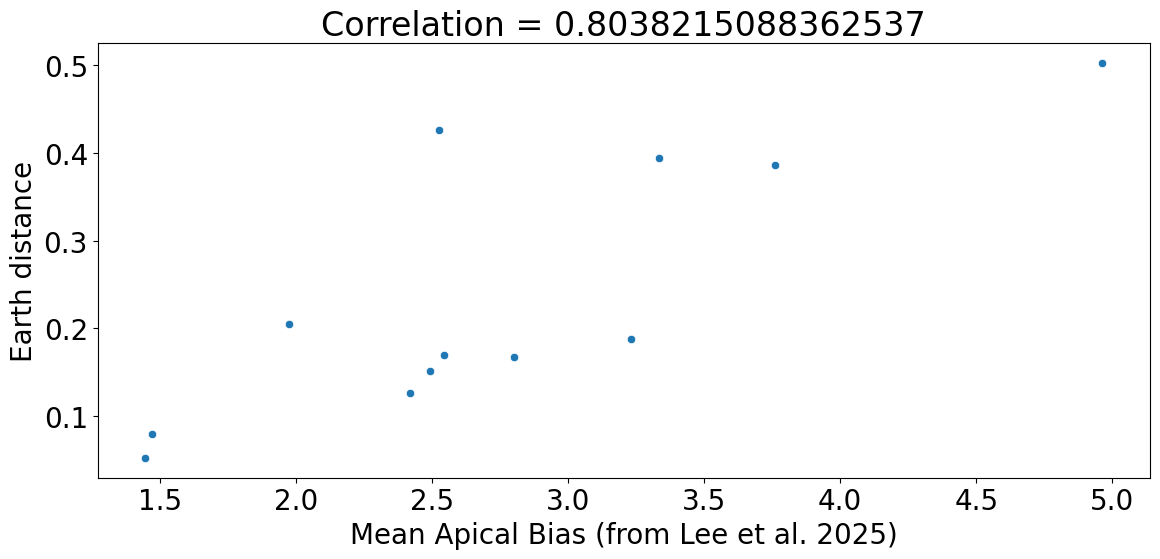

In [38]:
%matplotlib inline
plt.rcParams["figure.figsize"] = [12,6]
apical_merged = merged[merged["apical"]]
g = sns.scatterplot(data=apical_merged, x='mean_fc', y='earth_dist')
corr = apical_merged['mean_fc'].corr(apical_merged['earth_dist'])

plt.xlabel('Mean Apical Bias (from Lee et al. 2025)')
plt.ylabel('Earth distance')
plt.title(f'Correlation = {corr}')
saveAFigure(plt.gcf(), "8_lee_corr_between_apical_bias_and_earth_dist_total", out_dir=Path("/mnt/data/david/plots/manuscript/supplemental/"))
plt.show()

In [39]:
## Supp fig: classification scores of the false negatives
import math
from tqdm import tqdm
import matplotlib.gridspec as gridspec
false_negative_result_df = result_df[~(result_df["gene_pattern"].astype(bool)) & ~(result_df["true_random"])].copy()
out_base_dir = Path("/mnt/data/david/plots/manuscript/supplemental/moor_false_negatives_examples/")
out_base_dir.mkdir(exist_ok=True)

for tmp_row in tqdm(false_negative_result_df.itertuples()):
    pattern_score = np.array(tmp_row.pattern.obs["classifier_proba"])
    control_score = np.array(tmp_row.control.obs["classifier_proba"])
    row_text = pd.Series(tmp_row._asdict())[cols_of_interest].to_string()

    # one row of histogram + summary, then all observations ordered by pattern score
    n_cols = 5
    n_obs = len(tmp_row.pattern)
    n_rows = math.ceil(n_obs / n_cols)
    fig = plt.figure(figsize=(n_cols * 4, 8 + n_rows * 2))
    gs = gridspec.GridSpec(nrows=1 + n_rows, ncols=2 * n_cols, figure=fig, height_ratios=[3] + [1] * n_rows)

    ax_hist = fig.add_subplot(gs[0, 0:n_cols])
    ax_hist.hist(pattern_score, bins=50, alpha=0.6, label=tmp_row.gene_name, density=True, color=colorblind_palette[0])
    ax_hist.hist(control_score, bins=50, alpha=0.3, label="random", density=True, color=colorblind_palette[4])
    ax_hist.legend()
    ax_hist.set_title(f"Classifier scores, {tmp_row.bonferonni_pval}")

    ax_text = fig.add_subplot(gs[0, n_cols:])
    ax_text.text(0.5, 0.5, row_text, ha="center", va="center", fontsize=10, family="monospace")
    ax_text.set_axis_off()

    order = np.argsort(pattern_score)
    pattern_sorted = tmp_row.pattern[order]
    control_sorted = tmp_row.control[order]
    for i, (tmp_obs, tmp_ctrl) in enumerate(zip(pattern_sorted, control_sorted)):
        ax = fig.add_subplot(gs[1 + i // n_cols, i % n_cols]); ax.axis("off")
        plotFullDataPoint(single_cell_adata[getXYOfSingleCell(tmp_obs, 0)], ax=ax)
        ax.set_title(f"{tmp_obs.obs['classifier_proba'][0]:.2f}")
        ax = fig.add_subplot(gs[1 + i // n_cols, n_cols + i % n_cols]); ax.axis("off")
        plotFullDataPoint(single_cell_adata[getXYOfSingleCell(tmp_ctrl, 0)], row_coords="subcell_row_shuffled",
                          col_coords="subcell_col_shuffled", ax=ax, color="blue")
        ax.set_title(f"{tmp_ctrl.obs['classifier_proba'][0]:.2f}")

    fig.subplots_adjust(wspace=0.5, hspace=0.7)
    fig.savefig(out_base_dir / f"{tmp_row.gene_name}.png", bbox_inches="tight")
    fig.savefig(out_base_dir / f"{tmp_row.gene_name}.svg", bbox_inches="tight")
    plt.close(fig)


4it [00:26,  6.64s/it]


## Fig 6B

In [65]:
sc.pp.neighbors(adata, n_neighbors=30)

In [66]:
adjacency = sc._utils._choose_graph(adata, neighbors_key="neighbors",obsp=None)

In [67]:
g = sc._utils.get_igraph_from_adjacency(adjacency)

In [68]:
res = 0.6

In [69]:
clustering = g.community_leiden(objective_function='modularity', resolution_parameter=res,n_iterations=10)


/tmp/ipykernel_3816102/3850926258.py:1: DeprecationWarning: resolution_parameter keyword argument is deprecated, use resolution=... instead
  clustering = g.community_leiden(objective_function='modularity', resolution_parameter=res,n_iterations=10)


In [70]:
adata.obs[f'leiden_igraph_res_{res}'] = pd.Series(clustering.membership,  index=adata.obs.index).astype('category')


In [71]:
nr_leiden_clusters = len(list(set(adata.obs[f"leiden_igraph_res_{res}"])))
print(nr_leiden_clusters)

5


In [72]:
sc.tl.umap(adata)

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


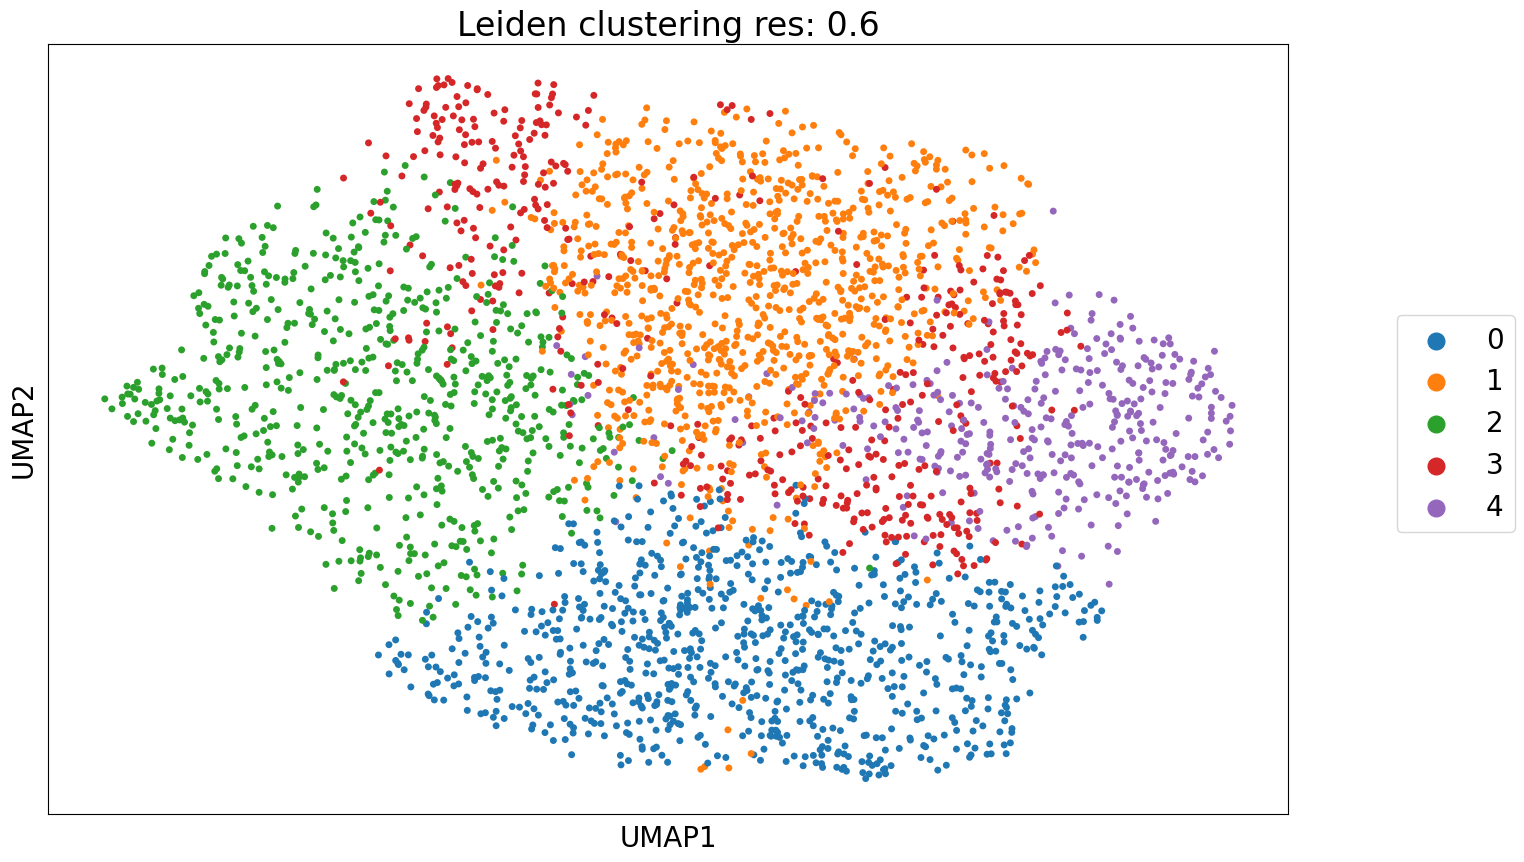

In [74]:
plt.rcParams["figure.figsize"] = [16,10]
fig = sc.pl.umap(adata, color=f'leiden_igraph_res_{res}', show=False, title=f"Leiden clustering res: {0.6}", s=100, return_fig=True)
handles, labels = fig.gca().get_legend_handles_labels()
fig.gca().legend().remove()
fig.legend(handles, labels, fontsize = 20, markerscale=2, bbox_to_anchor=(1.05, 0.5), loc='center right')

## Fig 6C

In [75]:
import matplotlib.pyplot as plt
import math

def create_custom_grid(num_axes):
    # Determine the grid size
    n_cols = math.ceil(math.sqrt(num_axes))
    n_rows = math.ceil(num_axes / n_cols)
    
    # Create figure
    fig = plt.figure(figsize=(8, 6))
    
    # Calculate basic sizes
    width = 0.8 / n_cols  # width of each subplot
    height = 0.8 / n_rows  # height of each subplot
    gap_x = (1 - (width * n_cols)) / (n_cols + 1)  # horizontal gap
    gap_y = (1 - (height * n_rows)) / (n_rows + 1)  # vertical gap
    
    for i in range(num_axes):
        row = i // n_cols
        col = i % n_cols
        
        # Special case: last row has fewer elements than the rest
        if row == n_rows - 1 and num_axes % n_cols != 0:
            extra_cols = num_axes % n_cols
            col_start = (n_cols - extra_cols) / 2  # offset to center subplots
            
            # Compute index *within* last row (not global i)
            index_in_row = i - row * n_cols
            col = col_start + index_in_row
            
        # Calculate position
        left = gap_x + (width + gap_x) * col
        bottom = 1 - gap_y - height - (height + gap_y) * row
        
        # Add subplot
        ax = fig.add_axes([left, bottom, width, height])
    
    return fig, fig.axes


In [76]:
def getCellThatHasObsInEachLeidenCluster(adata, leiden_key = "leiden"):
    df = adata.obs
    # Get the unique values in col1
    unique_col1_values = set(df[leiden_key].unique())

    # Group by col2 and find the unique values in col1 for each group
    groups = df.groupby('cell_id')[leiden_key].apply(set).reset_index()

    # Filter the groups where the set of unique values in col1 matches the unique values in the whole col1
    result = groups[groups[leiden_key] == unique_col1_values]

    # Extract the unique value(s) of col2 that satisfy the condition
    unique_values_in_col2 = result['cell_id'].tolist()

    return random.sample(unique_values_in_col2, 1)[0]


In [81]:
from skimage.filters import gaussian
plt.rcParams["figure.figsize"] = [16, 10]

def createInputImage(adata_for_one_obs):
    empty = np.zeros((100,100))
    detected_transcripts_for_this_cell = convertRecordToDf(adata_for_one_obs.obsm["detected_transcripts"][0])
    detected_transcripts_for_this_cell_gene = detected_transcripts_for_this_cell[detected_transcripts_for_this_cell["gene"] == adata_for_one_obs.var["gene_name"][0]]
    for tmp_row in detected_transcripts_for_this_cell_gene.itertuples():
        try:
            empty[tmp_row.subcell_row, tmp_row.subcell_col] = 1
        except IndexError:
            empty[tmp_row.subcell_row-1, tmp_row.subcell_col-1] = 1
    gauss = gaussian(empty, 1.5)
    return gauss

def plotAllDataFromLeidenCluster(full_adata, leiden_cluster, ax, leiden_key = "leiden",cell_id = None, model = None):
    combined_data_tmp = full_adata[full_adata.obs[leiden_key] == leiden_cluster]
    if combined_data_tmp.obs.empty:
        print("No data found")
        return
    # If we don't wanna decode, we look at original data
    if model is None:
        # if a cell id is given, we just wanna plot a random observation in a specific cell from this leiden cluster
        if cell_id is not None:
            combined_data_tmp = combined_data_tmp[combined_data_tmp.obs["cell_id"] == str(cell_id)]
            random_gene_in_this_cell = combined_data_tmp[0]
            # ur mom is done
            plotFullDataPoint(single_cell_adata[getXYOfSingleCell(combined_data_tmp, 0)], ax=ax)
            ax.set_title(combined_data_tmp.obs["gene_name"].iloc[0] + f", {leiden_cluster}")
            ax.axis("off")
        # if neither model nor cell are given, we just take all input
        else:
            images = []
            for tmp_row in combined_data_tmp:
                input_img = createInputImage(single_cell_adata[tmp_row.obs["original_obs_index"].iloc[0], tmp_row.obs["original_gene_index"].iloc[0]])
                images.append(input_img)
            mean_image = np.mean(np.array(images), axis=0)
            ax.imshow(mean_image)
            ax.set_title(leiden_cluster)
            ax.axis("off")
    
    else:
        midpoint = np.mean(combined_data_tmp.X, axis=0)
        decoded = decodeSubcellEmbedding(midpoint, subcellspace)
        ax.imshow(decoded)
        ax.set_title(leiden_cluster)
        ax.axis("off")
        return midpoint, decoded

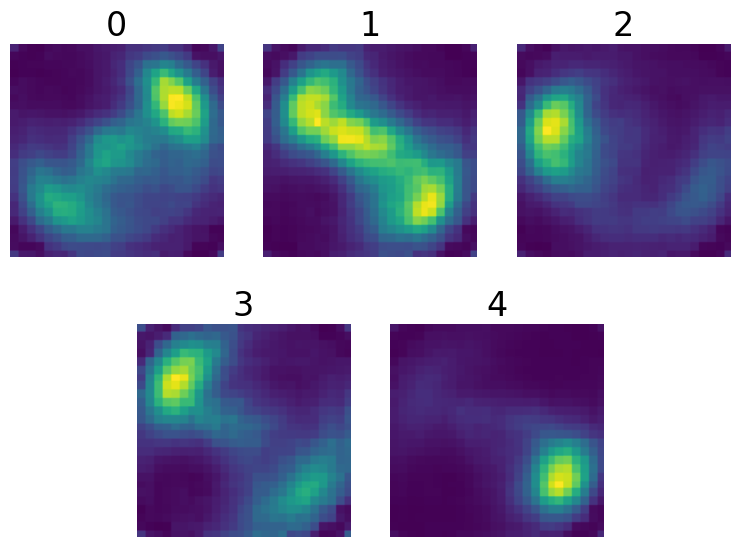

In [82]:
nr_leiden_clusters = len(adata.obs[f"leiden_igraph_res_{res}"].unique())
fig, axs = create_custom_grid(nr_leiden_clusters)
# axs = fig.axes
# axs = axs.flatten()
midpoint_dict = {}
images = {}
for leid in range(nr_leiden_clusters):
    midpoint, image = plotAllDataFromLeidenCluster(
        full_adata = adata,
        leiden_cluster = leid,
        ax=  axs[leid],
        model=subcellspace,
        leiden_key = f"leiden_igraph_res_{res}"
    )
    midpoint_dict[leid] = midpoint
    images[leid] = image

### Get closest X observations to midpoint

In [83]:
from scipy import spatial

coord_list = []
for row in adata.X:
    coord_list.append(tuple(row))
tree = spatial.KDTree(coord_list)

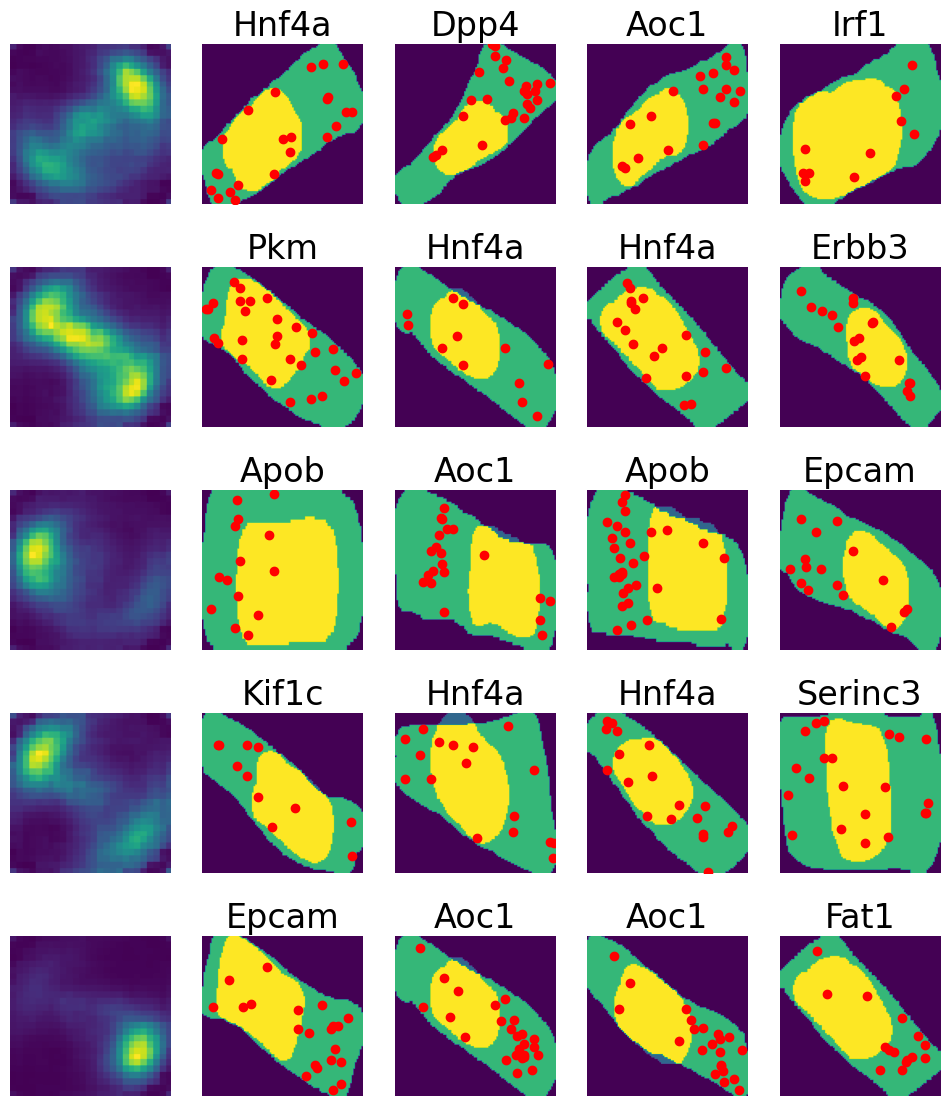

In [90]:
n =4 
plt.rcParams["figure.figsize"] = [12,14]
fig, axs = plt.subplots(len(midpoint_dict),n+1)
for ax in axs.flatten():
    ax.axis("off")
for leid, point in midpoint_dict.items():
    axs[leid,0].imshow(images[leid])
    
    closest_indices = tree.query([point], k=4)[1][0]
    for i, index in enumerate(closest_indices):
        plotFullDataPoint(single_cell_adata[getXYOfSingleCell(adata, index)], ax=axs[leid, i+1])
        axs[leid, i+1].set_title(single_cell_adata[getXYOfSingleCell(adata, index)].var_names[0])

## Fig 6D

In [91]:
cell_apical_basal_leiden_cluster = []

for cell_id in list(single_cell_adata.obs_names):
    cell_specific_adata = adata[adata.obs["cell_id"] == cell_id]
    genes_in_cell = list(cell_specific_adata.obs["gene_name"].unique())
    if ("Apob" in genes_in_cell):
        cell_adata_with_apob = cell_specific_adata[cell_specific_adata.obs["gene_name"] == "Apob"]
        assert len(cell_adata_with_apob) == 1
        leiden_cluster = cell_adata_with_apob.obs[f"leiden_igraph_res_{res}"][0]

    else:
        leiden_cluster=999
    cell_apical_basal_leiden_cluster.append(leiden_cluster)

        

In [102]:
leiden_mapping = {0: "right", 1: "random", 2: "left", 3: "left", 4: "right", 999:"Apob not present"} 
# Leiden mapping visually determined, order might be different due to leiden clustering stochasticity
single_cell_adata.obs["Apob_in"] = cell_apical_basal_leiden_cluster
single_cell_adata.obs["Apob_points_to"] = single_cell_adata.obs["Apob_in"].apply(lambda x: leiden_mapping[x])

In [103]:
adata.obs["points_to"] = adata.obs["leiden_igraph_res_0.6"].apply(lambda x: leiden_mapping[x])  

In [104]:
adata.obs["leiden"] = adata.obs["leiden_igraph_res_0.6"].copy()

In [105]:
# Colour umap by apob pointing or nothing
apob_points_list = []
for tmp_row in adata.obs.itertuples():
    tmp_row = tmp_row._asdict()
    if tmp_row["gene_name"] != "Apob":
        apob_points_list.append("No Apob")
        continue
    apob_in = leiden_mapping[tmp_row["leiden"]]
    apob_points_list.append(apob_in)
adata.obs["apob_points_to"] = apob_points_list    

In [110]:
global_cmap = get_cmap(4)
# cmap = get_cmap(len(adata.obs["pattern"].unique()), name="tab10")
palette = {}
for i, el in enumerate(("right", "No Apob", "left", "random")):
    palette[el] =  global_cmap(i)

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1171: FutureWarning: In a future version of pandas all arguments of Categorical.replace except for the argument 'value' will be keyword-only.
  values = values.replace(values.categories.difference(groups), np.nan)
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1171: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


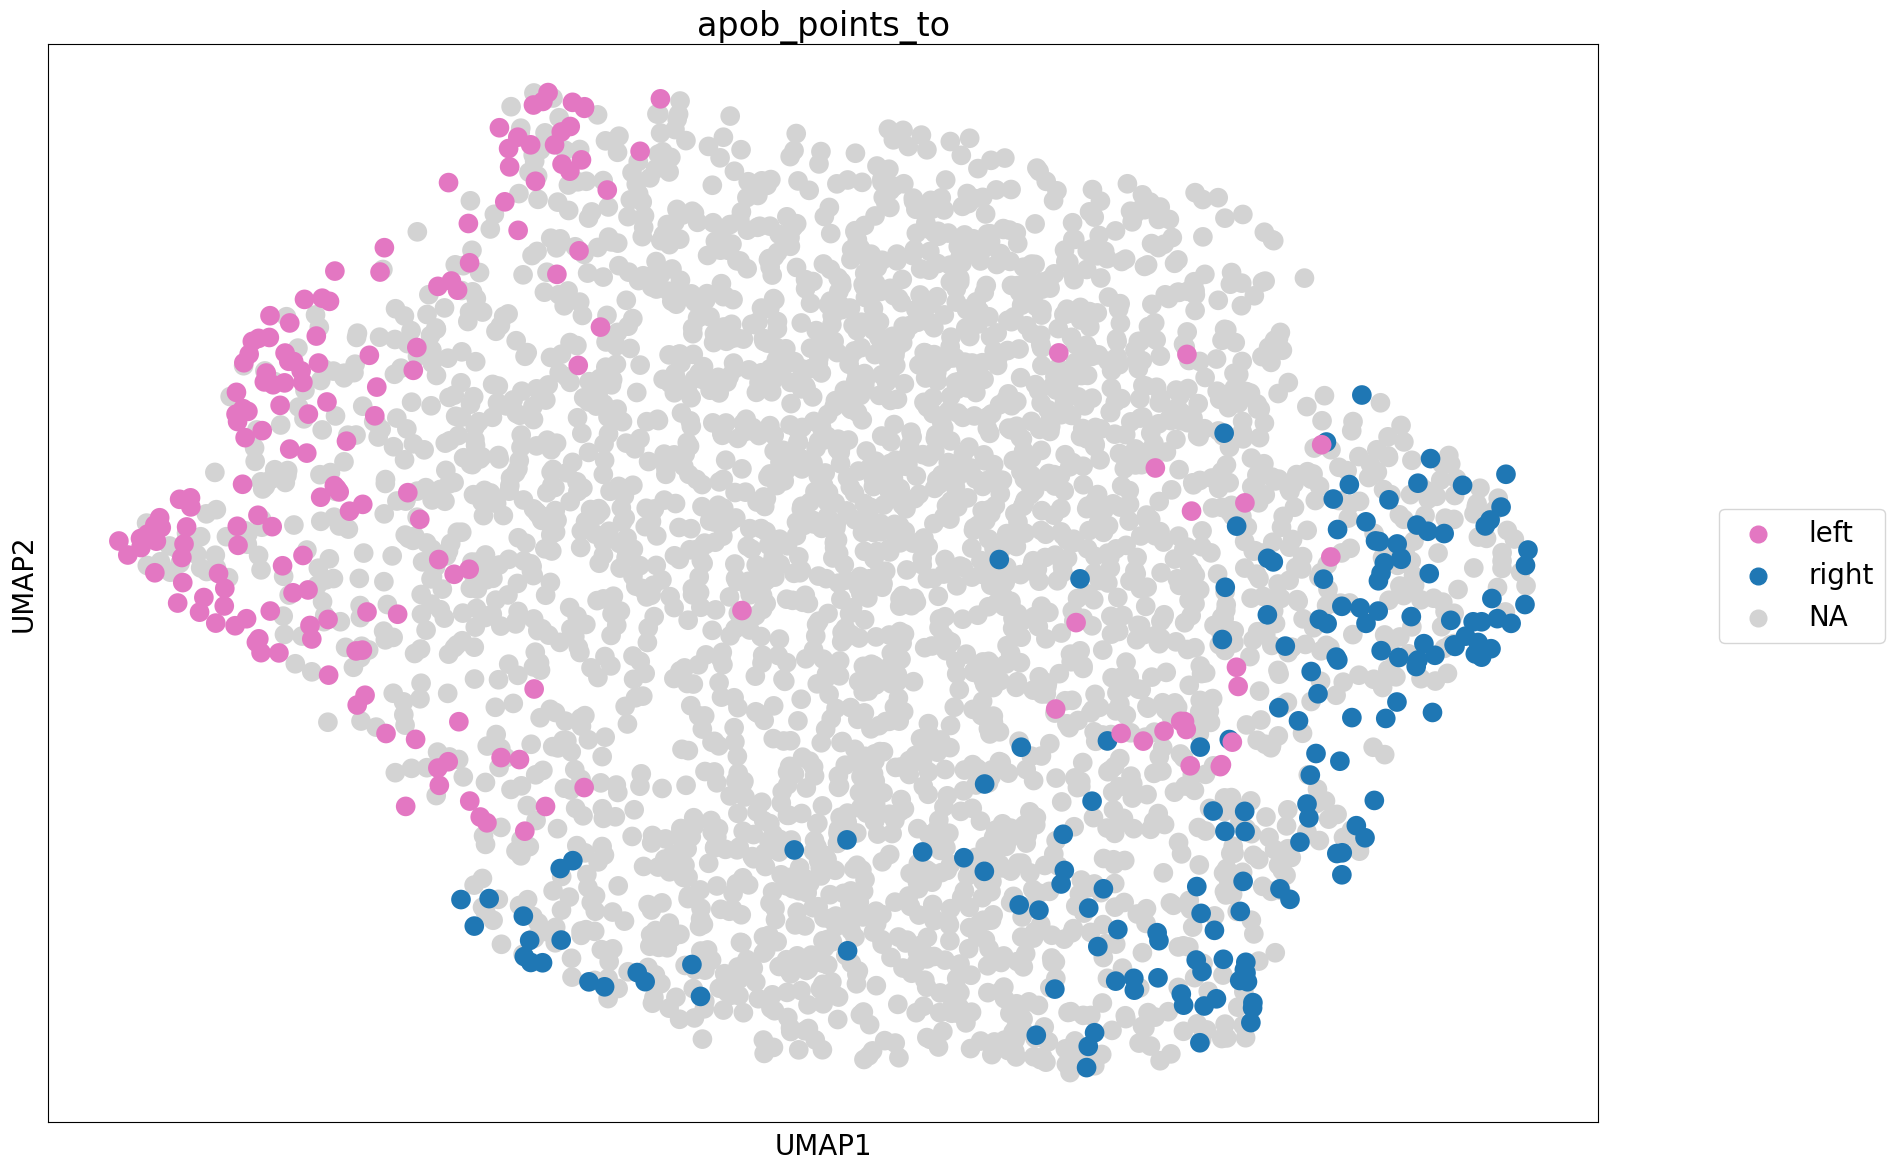

In [111]:
plt.rcParams["figure.figsize"] = 20,14
fig = sc.pl.umap(adata, color="apob_points_to", groups=("left", "right"), s=800, palette = palette, return_fig=True)
handles, labels = fig.gca().get_legend_handles_labels()
fig.gca().legend().remove()
fig.legend(handles, labels, fontsize = 20, markerscale=2, bbox_to_anchor=(1.05, 0.5), loc='center right')

In [288]:
saveAFigure(fig, "Apob_points_to_umap", rasterize=True, out_dir = distance_out_dir)

# Fig 6E

In [114]:
img = io.imread(data_dir / "small_intestine_data" / "merfish_data" / "polyt_on_dapi_overlay_image.tif")

In [115]:
slc = np.s_[1700:3500, 7200:8000]

In [116]:
import numpy as np

def point_in_slice(point, slc):
    if (point[0] < slc[0].start) or (point[0] > slc[0].stop):
        return False
    if (point[1] < slc[1].start) or (point[1] > slc[1].stop):
        return False
    else:
        return True


In [117]:
from skimage.segmentation import mark_boundaries
segmentation_mask = io.imread(data_dir / "small_intestine_data" / "merfish_data" / "segmentation_mask.tif")
overlay = mark_boundaries(img, segmentation_mask)

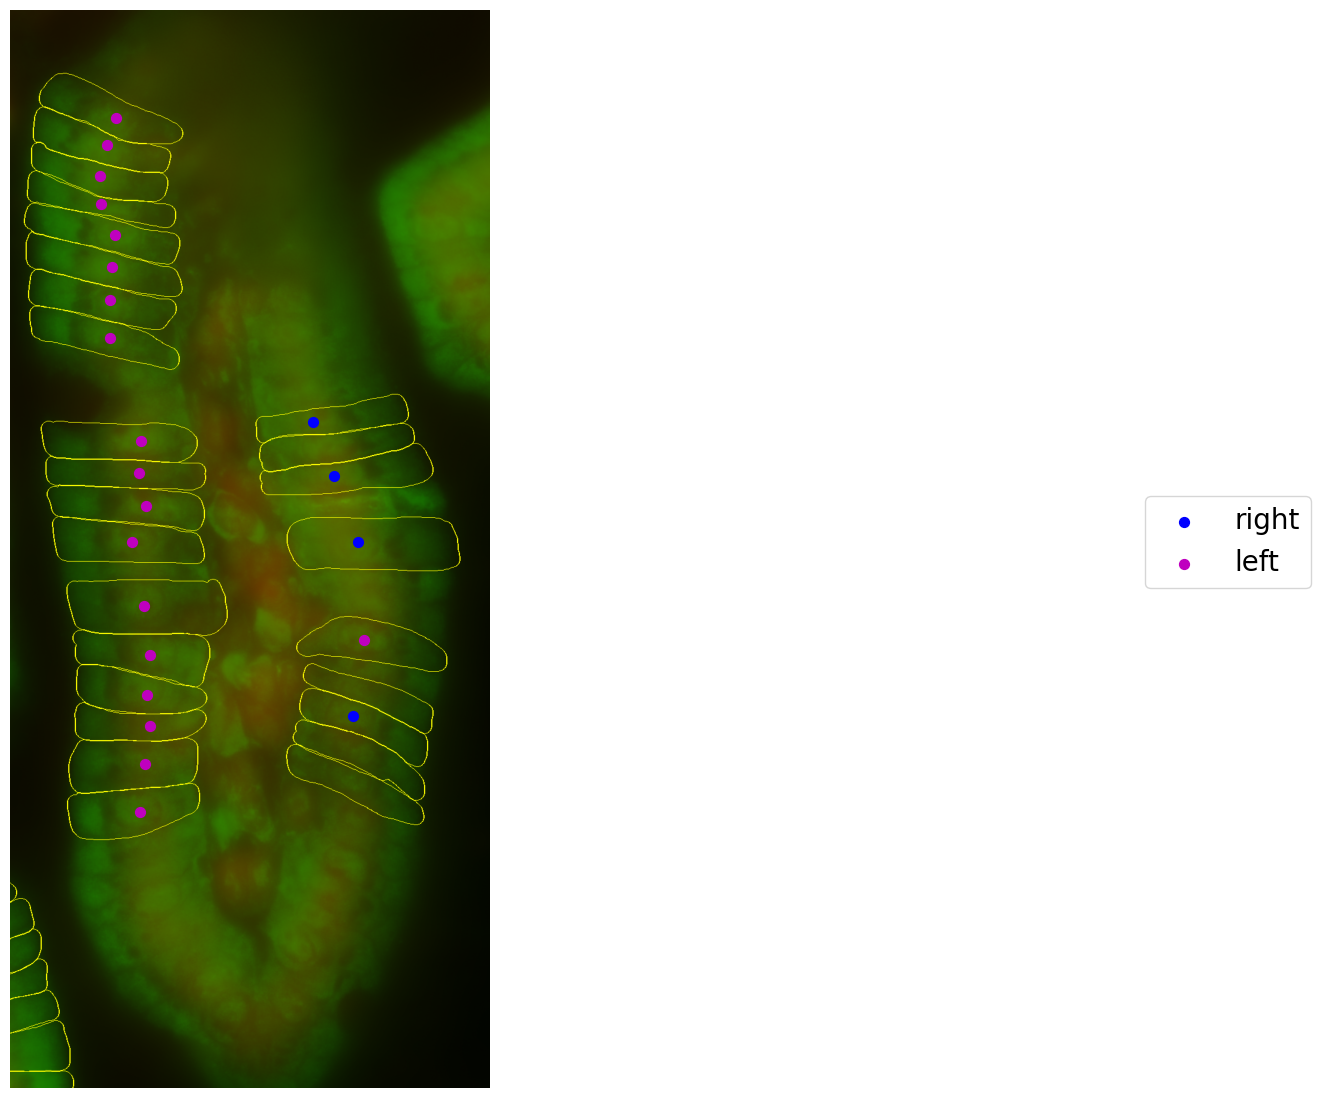

In [120]:
from skimage.segmentation import mark_boundaries
import ast
%matplotlib inline
def plotOriginalLocation(adata, color_by):
    # It might be that the given adata is a filtered version, so we only look at the single cells who are actually in the thing
    tmp_single_cell_adata = single_cell_adata[single_cell_adata.obs["name"].isin(adata.obs["cell_id"])]

    fig, ax = plt.subplots(1,1)
    ax.imshow(overlay[slc[0], slc[1], :])
    colors = ['b', 'm', 'y', "c", 'r']
    ax.axis("off")
    for i, direction in enumerate(["right", "left"]):
        even_more_tmp_single_cell_adata = tmp_single_cell_adata[tmp_single_cell_adata.obs["Apob_points_to"] == direction]
        even_more_tmp_single_cell_adata = even_more_tmp_single_cell_adata[[point_in_slice((tmp_row.local_row, tmp_row.local_col), slc) for tmp_row in even_more_tmp_single_cell_adata.obs.itertuples()]]

                
        ax.scatter(even_more_tmp_single_cell_adata.obs["local_col"] - slc[1].start, even_more_tmp_single_cell_adata.obs["local_row"] - slc[0].start, c=colors[i], label = direction, s=50)    
    fig.legend(loc='center right', bbox_to_anchor=(1.05, 0.5))
    return fig
tile_to_check="44"
gene_mask = [True] * len(adata)
tile_mask = adata.obs["tile_nr"] == tile_to_check
cells_to_plot = adata.obs["tile_nr"] == tile_to_check

fig = plotOriginalLocation(adata[(gene_mask) & (tile_mask)], color_by = "Apob_points_to")

## Fig 6E-F

In [124]:
from sklearn.metrics.pairwise import cosine_similarity,euclidean_distances
import ot

In [125]:
def calculate_cosine_similarity(matrix1, matrix2):
    M = ot.dist(matrix1, matrix2, metric="cosine")
    return np.mean(M)
    

In [214]:
def plot_genes_side_by_side(adata, gene1, gene2, cell_id=None, ax=None, color1="red", color2="blue", size= 10):
    if ax is None:
        fig, ax = plt.subplots(1,1)
        
    genes = adata.obs["gene_name"]
    
    cell_ids = adata.obs["cell_id"]
    
    for index, (tmp_gene, tmp_cell_id) in enumerate(zip(genes,cell_ids)):
        if tmp_gene == gene1 and tmp_cell_id == cell_id:
            matching_index1 = index

        if tmp_gene == gene2 and tmp_cell_id == cell_id:
            matching_index2 = index
    
    
    plotFullDataPoint(single_cell_adata[getXYOfSingleCell(adata, matching_index1)], ax = ax, color=color1, size=size)
    plotFullDataPoint(single_cell_adata[getXYOfSingleCell(adata, matching_index2)], ax = ax, color=color2, size=size)
    return matching_index1, matching_index2


In [135]:
# changed genes to pattern to test with simulate data
bidirectional_dict_gene_pair_dict = {}

cell_id_counts = adata.obs["cell_id"].value_counts()
for cell_id, count in tqdm(cell_id_counts.items(), total = len(cell_id_counts)):
    if count > 1:
        cell_specific_real_pattern_adata = adata[adata.obs["cell_id"]==cell_id]
        genes_in_this_cell = list(cell_specific_real_pattern_adata.obs["gene_name"].unique())
        for i, gene1 in enumerate(genes_in_this_cell):
            for gene2 in genes_in_this_cell[i+1:]:
                pair_key = tuple(sorted((gene1, gene2)))
                gene1_arr = np.array(cell_specific_real_pattern_adata[cell_specific_real_pattern_adata.obs["gene_name"] == gene1].X)
                gene2_arr = np.array(cell_specific_real_pattern_adata[cell_specific_real_pattern_adata.obs["gene_name"] == gene2].X)
                
                similarity = calculate_cosine_similarity(gene1_arr, gene2_arr)
                
                if pair_key in bidirectional_dict_gene_pair_dict:
                    bidirectional_dict_gene_pair_dict[pair_key].append(similarity)
                else:
                    bidirectional_dict_gene_pair_dict[pair_key] = [similarity]



100%|████████████████████████████████████████████████████████████████████████████████████████████████| 407/407 [01:01<00:00,  6.62it/s]


In [136]:
list_of_gene_pairs_and_their_mean_values = []
for k, v in bidirectional_dict_gene_pair_dict.items():
    if len(v) > 4:
        list_of_gene_pairs_and_their_mean_values.append((k[0], k[1], np.mean(v), len(v)))
    

In [196]:
sorted_list_of_gene_pairs_and_their_mean_values = sorted(list_of_gene_pairs_and_their_mean_values, key=lambda x: x[2], reverse=False)

top_n_similar_pairs = sorted_list_of_gene_pairs_and_their_mean_values

for i, pair in enumerate(top_n_similar_pairs):
    gene1, gene2, similarity, n_observations = pair
    print(f"{i}: {gene1}-{gene2} have a distance of {similarity} with {n_observations} observations")

0: Fos-Uqcrfs1 have a distance of 0.02735297696979431 with 5 observations
1: Aoc1-Clca4b have a distance of 0.03869889166178037 with 187 observations
2: Nlrp6-Serinc3 have a distance of 0.03918656294084636 with 6 observations
3: Aoc1-Apob have a distance of 0.04299480825321351 with 274 observations
4: Dpp4-Fos have a distance of 0.04705549881697172 with 7 observations
5: Irf1-Serinc3 have a distance of 0.04732901156936478 with 17 observations
6: Hnf4a-Nlrp6 have a distance of 0.04743904693255754 with 22 observations
7: Nlrp6-Uqcrfs1 have a distance of 0.047940787594105395 with 9 observations
8: Ceacam1-Fat1 have a distance of 0.04831057885188688 with 9 observations
9: Apob-Clca4b have a distance of 0.048728725401225234 with 204 observations
10: Ctnnb1-Eif4h have a distance of 0.04884551930823361 with 17 observations
11: Eif4h-Nlrp6 have a distance of 0.04979770167073315 with 21 observations
12: Aoc1-Cdh1 have a distance of 0.04999200931110517 with 8 observations
13: Eif4h-Uqcrfs1 have 

In [193]:
four_random_colors = get_cmap(4)

In [197]:
# Reorder cmap for this specific figure:
def reordered_cmap(four_random_colors, i):
    mapping = {
        0: 0, 
        1: 3,
        2: 1,
        3: 2
    }
    return four_random_colors(mapping[i])

In [209]:
plt.rcParams["figure.figsize"] = [14,10]

The labels and colors here are mostly hardcoded for the manuscript , do not blindly reuse
Aoc1 Apob
Aoc1 Apob


/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  cax = scatter(


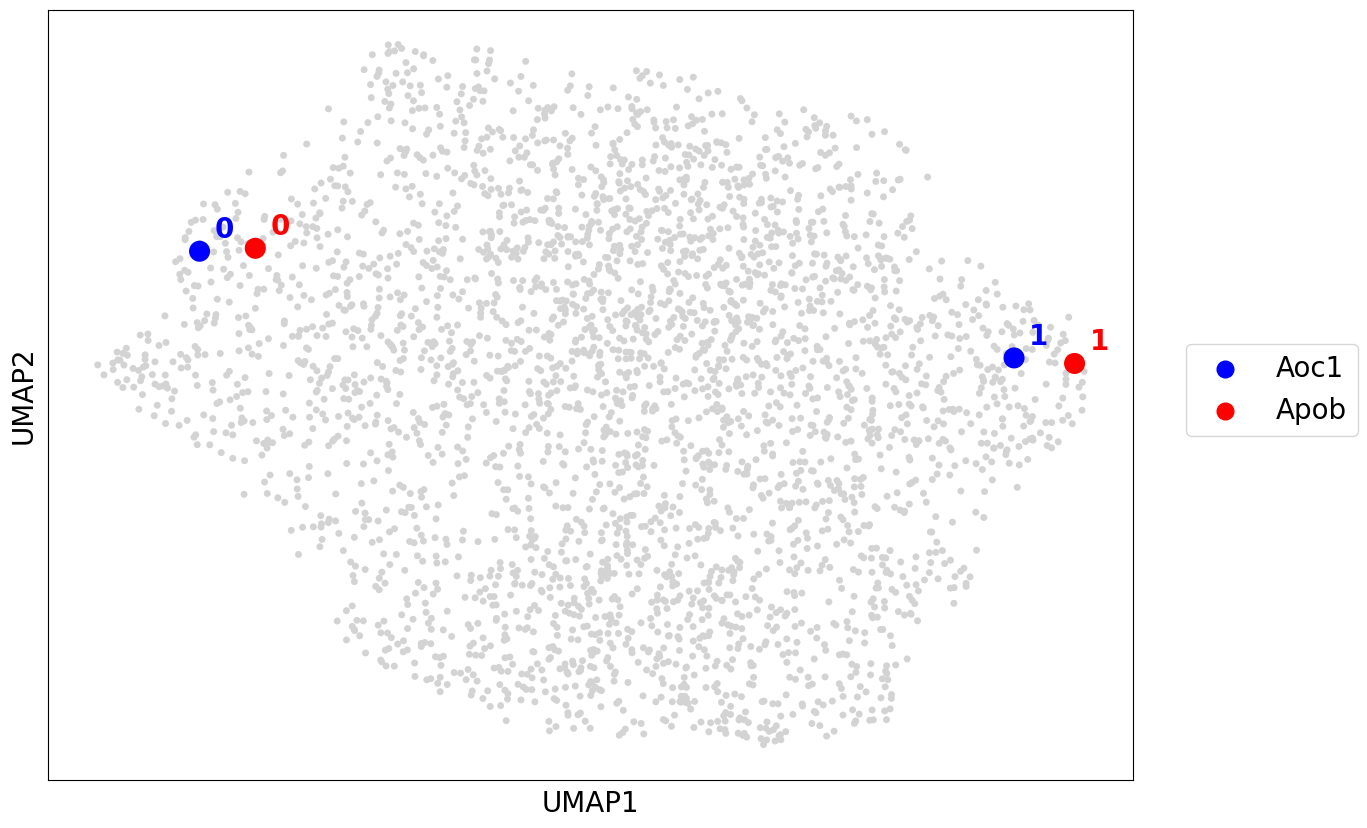

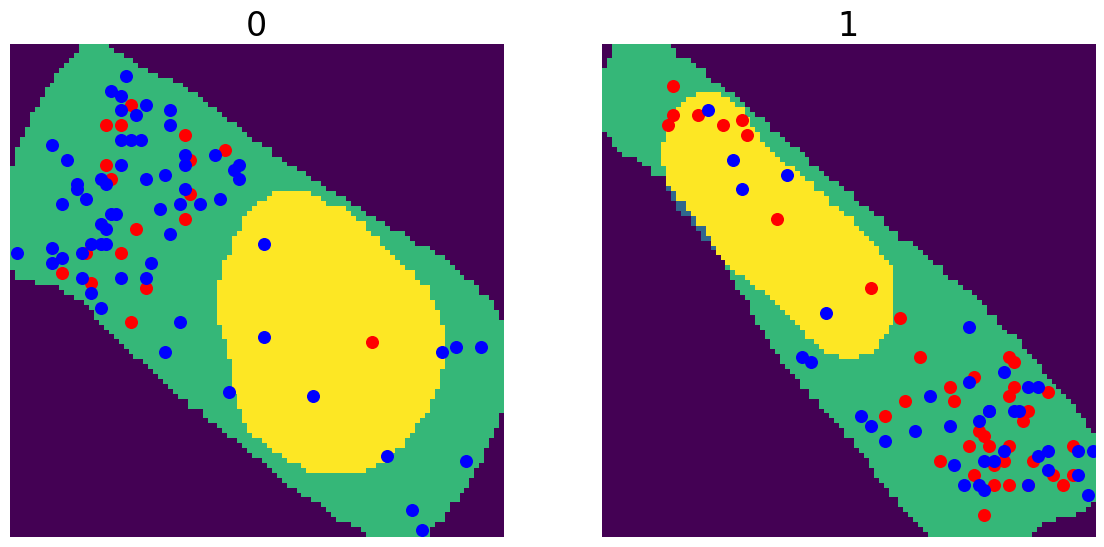

In [222]:
print("The labels and colors here are mostly hardcoded for the manuscript , do not blindly reuse")
top_pair = 3
bottom_pair = 387
for i, pair in enumerate(top_n_similar_pairs):
    if i == top_pair:
        gene1, gene2, similarity, n_observations = pair
        # Define the specific gene values you want to search for
        target_genes = [gene1, gene2]

        # Use boolean indexing to find cells that have both specific gene values
        result = adata.obs[adata.obs['gene_name'].isin(target_genes)] # take all instances of the 2 genes
        result = result.groupby('cell_id').filter(lambda x: len(x) == len(target_genes))

        # Get the unique cell values that meet the criteria
        gene1_and_gene2_specific_cells = result['cell_id'].unique()
    #             assert len(gene1_and_gene2_specific_cells)==n_observations
        #get_fake_legend
    # FAke plot for handles and labels
        fig, ax = plt.subplots(1,1)
        ax.scatter(1,1, color="blue", label=gene1)
        ax.scatter(0,0, color="red", label=gene2)

        handles, labels = fig.gca().get_legend_handles_labels()
        plt.close()

        fig_umap, axs_umap = plt.subplots(1,1)
        sc.pl.umap(adata, color = None, ax = axs_umap, s=100, show=False)
        fig_umap.legend(handles, labels, fontsize = 20, markerscale=2, bbox_to_anchor=(1.07, 0.5), loc='center right')

        # Try adata 
        fig, axs = plt.subplots(1,2)
        axs = axs.flatten()
        for ax in axs:
            ax.axis("off")

        random.seed(110)
        four_random_cells = random.sample(list(gene1_and_gene2_specific_cells), 4)

        for j, cell_id in enumerate(four_random_cells[:2]):
            print(gene1, gene2)
            if j >= 4:
                break
            matching_index1, matching_index2 = plot_genes_side_by_side(adata, gene1, gene2, cell_id =cell_id, ax = axs[j], color1="red", color2="blue", size=70)

            matching_point1 = adata[matching_index1].obsm["X_umap"][0]
            matching_point2 = adata[matching_index2].obsm["X_umap"][0]

            axs_umap.scatter([matching_point1[0], matching_point2[0]], [matching_point1[1], matching_point2[1]], color=["red", "blue"], s=200)
        # Add text labels near each point
            axs_umap.text(
                matching_point1[0] + 0.2,  # small x offset for visibility
                matching_point1[1] + 0.2,
                f"{j}",
                color="red",
                fontsize=20,
                weight="bold"
            )
            axs_umap.text(
                matching_point2[0] + 0.2,
                matching_point2[1] + 0.2,
                f"{j}",
                color="blue",
                fontsize=20,
                weight="bold"
            )
            axs[j].set_title(j)
    #             fig.legend(handles, labels, fontsize = 20, markerscale=2, bbox_to_anchor=(1.07, 0.5), loc='center right')

    #             fig_umap


The labels and colors here are mostly hardcoded for the manuscript , do not blindly reuse
Apob Pigr
Apob Pigr


/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  cax = scatter(


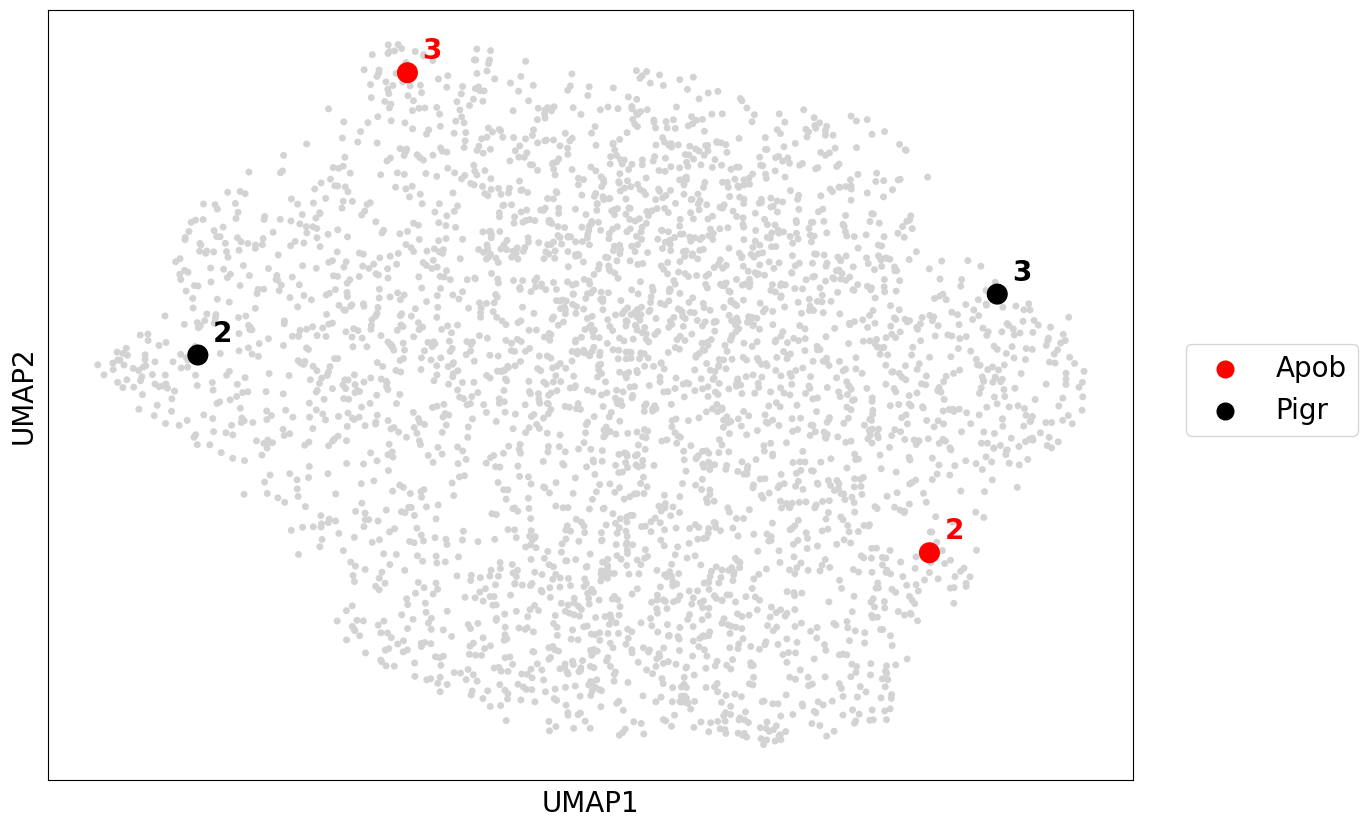

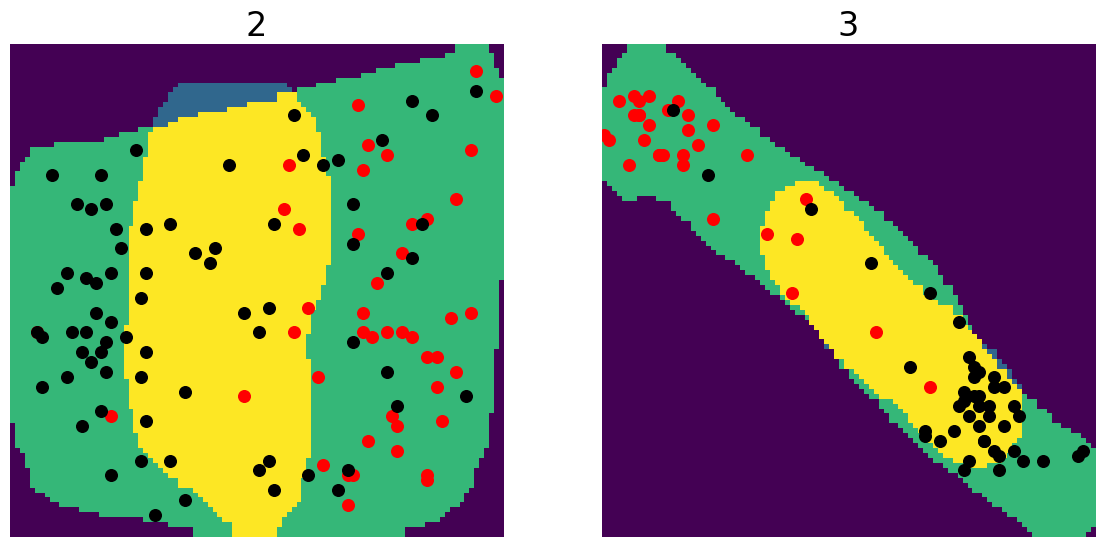

In [220]:
print("The labels and colors here are mostly hardcoded for the manuscript , do not blindly reuse")
bottom_pair = 387
color2 = "black"
for i, pair in enumerate(top_n_similar_pairs):
    if i == bottom_pair:
        gene1, gene2, similarity, n_observations = pair
        # Define the specific gene values you want to search for
        target_genes = [gene1, gene2]

        # Use boolean indexing to find cells that have both specific gene values
        result = adata.obs[adata.obs['gene_name'].isin(target_genes)] # take all instances of the 2 genes
        result = result.groupby('cell_id').filter(lambda x: len(x) == len(target_genes))

        # Get the unique cell values that meet the criteria
        gene1_and_gene2_specific_cells = result['cell_id'].unique()
    #             assert len(gene1_and_gene2_specific_cells)==n_observations
        #get_fake_legend
    # FAke plot for handles and labels
        fig, ax = plt.subplots(1,1)
        ax.scatter(1,1, color="red", label=gene1)
        ax.scatter(0,0, color=color2, label=gene2)

        handles, labels = fig.gca().get_legend_handles_labels()
        plt.close()

        fig_umap, axs_umap = plt.subplots(1,1)
        sc.pl.umap(adata, color = None, ax = axs_umap, s=100, show=False)
        fig_umap.legend(handles, labels, fontsize = 20, markerscale=2, bbox_to_anchor=(1.07, 0.5), loc='center right')
        # Try adata 
        fig, axs = plt.subplots(1,2)
        axs = axs.flatten()
        for ax in axs:
            ax.axis("off")

        random.seed(151)
        four_random_cells = random.sample(list(gene1_and_gene2_specific_cells), 2)

        for j, cell_id in enumerate(four_random_cells, 2):
            print(gene1, gene2)
            if j >= 4:
                break
            matching_index1, matching_index2 = plot_genes_side_by_side(adata, gene1, gene2, cell_id =cell_id, ax = axs[j-2], color1="red", color2=color2, size=70)

            matching_point1 = adata[matching_index1].obsm["X_umap"][0]
            matching_point2 = adata[matching_index2].obsm["X_umap"][0]

            axs_umap.scatter([matching_point1[0], matching_point2[0]], [matching_point1[1], matching_point2[1]], color=["red", color2], s=200)
            

        # Add text labels near each point
            axs_umap.text(
                matching_point1[0] + 0.2,  # small x offset for visibility
                matching_point1[1] + 0.2,
                f"{j}",
                color="red",
                fontsize=20,
                weight="bold"
            )
            axs_umap.text(
                matching_point2[0] + 0.2,
                matching_point2[1] + 0.2,
                f"{j}",
                color=color2,
                fontsize=20,
                weight="bold"
            )
            axs[j-2].set_title(j)

    #             fig_umap
